# alftrade Demo

A pedagogical **A-share low-frequency cross-sectional trading system** (daily signal frequency). Factors are computed in one **polars-vectorized** pass over a **parquet-by-date** panel, and the full pipeline — including ingesting **real A-share data** — runs off disk.

**Architecture:**
```
generate_simulated_market()  →  write_market_parquet()  →  marketdata/*.parquet + index.parquet
         (or real data via ingest_parquet)                         ↓ (polars read)
                              compute_factor_panel()  →  {date: {symbol: factors}}
                                                                    ↓
TradingEngine.on_cross_section(date, bars)  →  cross-sectional standardization  →  {symbol: [Signal]}
                                                                    ↓
SignalAggregator  →  CompositeSignal  →  PortfolioManager.decide()  →  [Trade]
                                                ↓                    ↓
                                        RiskManager            RiskManager
                                        .check_pre_trade()     .check_post_bar()
                                                ↓                    ↓
                                          Portfolio.apply_trade()  →  PnL
```

**A-share specifics:** long-only · T+1 · ±10% price limit · 100-share board lot ·
commission + stamp duty · Fama-MacBeth cross-sectional calibration · market-beta
neutralisation · short-index-futures hedge.

**Sections:**
- §1–§2b: polars factor computation, the parquet data layer, and real-data ingest
- §3–§7: cross-sectional signals, Fama-MacBeth calibration, factor profiling
- §8–§12: portfolio rebalancing, equity, turnover, style exposure, hedge, risk


In [23]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import os, tempfile

from alftrade import (
    DailyBar, StockUniverse, generate_simulated_market, bars_to_frame, frame_to_bars,
    FACTOR_NAMES, compute_factor_panel, factor_panel_to_dict,
    Signal, TradingEngine,
    Position, Trade, Portfolio, CostModel, CompositeSignal,
    SignalAggregator, PortfolioManager,
    RiskManager, RiskConfig,
    CalibrationResult, FactorCalibrator,
    FactorProfile, ModelProfile, FactorProfiler,
    HedgeManager, FuturesContract, compute_hedged_equity,
    write_market_parquet, ParquetPanel, load_market_parquet,
    load_factor_panel, load_market_with_factors,
    ingest_parquet,
)

plt.rcParams["figure.dpi"] = 110
np.random.seed(42)
print("alftrade ready —", len(FACTOR_NAMES), "factors via polars")

alftrade ready — 11 factors via polars


---

# Part I — Factors & Signals

## 1. Vectorized Factor Computation (polars)

``compute_factor_panel`` takes a **long** DataFrame (one row per symbol×date) and
computes all 11 factors in a single pass using ``.over("symbol")`` window
expressions — no per-stock Python loops.

In [24]:
rows = [
    {"date": 1, "symbol": "A", "open": 100.0, "high": 101.0, "low": 99.0,
     "close": 100.5, "volume": 1000.0, "prev_close": 100.0, "market_return": 0.005},
    {"date": 2, "symbol": "A", "open": 100.5, "high": 102.0, "low": 100.0,
     "close": 101.5, "volume": 1200.0, "prev_close": 100.5, "market_return": -0.002},
    {"date": 3, "symbol": "A", "open": 101.5, "high": 103.0, "low": 101.0,
     "close": 102.0, "volume": 1500.0, "prev_close": 101.5, "market_return": 0.008},
    {"date": 1, "symbol": "B", "open": 50.0, "high": 50.5, "low": 49.5,
     "close": 50.2, "volume": 800.0, "prev_close": 50.0, "market_return": 0.005},
    {"date": 2, "symbol": "B", "open": 50.2, "high": 51.0, "low": 50.0,
     "close": 50.8, "volume": 900.0, "prev_close": 50.2, "market_return": -0.002},
    {"date": 3, "symbol": "B", "open": 50.8, "high": 51.5, "low": 50.5,
     "close": 51.0, "volume": 1100.0, "prev_close": 50.8, "market_return": 0.008},
]
print(compute_factor_panel(pl.DataFrame(rows)))

shape: (6, 13)
┌──────┬────────┬──────────────┬─────────────┬───┬─────────────┬────────┬────────────┬─────────────┐
│ date ┆ symbol ┆ daily_return ┆ overnight_r ┆ … ┆ volume_rati ┆ rsi_14 ┆ atr_pct_14 ┆ market_beta │
│ ---  ┆ ---    ┆ ---          ┆ eturn       ┆   ┆ o           ┆ ---    ┆ ---        ┆ ---         │
│ i64  ┆ str    ┆ f64          ┆ ---         ┆   ┆ ---         ┆ f64    ┆ f64        ┆ f64         │
│      ┆        ┆              ┆ f64         ┆   ┆ f64         ┆        ┆            ┆             │
╞══════╪════════╪══════════════╪═════════════╪═══╪═════════════╪════════╪════════════╪═════════════╡
│ 1    ┆ A      ┆ 0.005        ┆ 0.0         ┆ … ┆ 1.0         ┆ 0.0    ┆ 0.0199     ┆ 1.0         │
│ 2    ┆ A      ┆ 0.00995      ┆ 0.0         ┆ … ┆ 1.090909    ┆ 1.0    ┆ 0.019704   ┆ 1.0         │
│ 3    ┆ A      ┆ 0.004926     ┆ 0.0         ┆ … ┆ 1.216216    ┆ 1.0    ┆ 0.019608   ┆ 1.0         │
│ 1    ┆ B      ┆ 0.004        ┆ 0.0         ┆ … ┆ 1.0         ┆ 0.0    ┆ 0.

## 2. Real-Data Simulation — Parquet-by-Date Access

Write the in-memory panel to **one parquet per date**, then read it back with
polars exactly as a production pipeline would.

In [25]:
bars_by_date, universe, market_returns = generate_simulated_market(
    n_stocks=5, n_days=40, seed=3)
root = tempfile.mkdtemp(prefix="alftrade_")
write_market_parquet(bars_by_date, universe, market_returns, root)
print("Files written:", sorted(os.listdir(os.path.join(root, "marketdata")))[:5], "...")

sample_date = sorted(bars_by_date)[-1]
df = pl.read_parquet(f"{root}/marketdata/{sample_date}.parquet")
print("Schema:", dict(df.schema))

Files written: ['20200101.parquet', '20200102.parquet', '20200103.parquet', '20200104.parquet', '20200105.parquet'] ...
Schema: {'date': Int64, 'symbol': String, 'open': Float64, 'high': Float64, 'low': Float64, 'close': Float64, 'volume': Float64, 'amount': Float64, 'prev_close': Float64, 'limit_up_price': Float64, 'limit_down_price': Float64, 'is_suspended': Boolean, 'total_shares': Float64}


In [26]:
panel, uni2, mkt2 = load_market_parquet(root)
loaded = panel[sample_date]
sym = list(loaded)[0]
o, l = bars_by_date[sample_date][sym], loaded[sym]
print(f"Round-trip {sym}: close {o.close} → {l.close}, market_return {o.market_return} → {l.market_return}")
assert o.close == l.close and o.market_return == l.market_return
print("Round-trip OK")

Round-trip 600000.SH: close 37.48358102177608 → 37.48358102177608, market_return -0.009970836367217139 → -0.009970836367217139
Round-trip OK


## 2b. Ingesting *Real* A-share Data

``ingest_parquet`` bridges a real vendor feed into the standard schema.  Here we
ingest **actual 1-minute A-share bars** (``chn_equ_hf_1minbar`` parquet-by-date),
aggregate to daily OHLCV, and derive ``prev_close`` / limit prices / market return.

In [27]:
REAL_SRC = "/home/hongbo/projects/hf2lf_factors/chn_equ_hf_1minbar"
if os.path.isdir(REAL_SRC):
    real_df = ingest_parquet(REAL_SRC, intraday=True)
    print(f"Ingested real A-share 1-min bars → daily: {real_df.shape}")
    print(real_df[["date", "symbol", "open", "high", "low", "close",
                   "volume", "prev_close", "limit_up_price", "market_return"]])
    factors_real = compute_factor_panel(real_df)
    print("Factors from real data:")
    print(factors_real[["date", "symbol", "daily_return", "volatility_20d", "market_beta"]])
else:
    print("Real data directory not found — skipping (run on a machine with chn_equ_hf data).")

Ingested real A-share 1-min bars → daily: (8, 14)
shape: (8, 10)
┌──────────┬───────────┬───────┬───────┬───┬──────────────┬────────────┬─────────────┬─────────────┐
│ date     ┆ symbol    ┆ open  ┆ high  ┆ … ┆ volume       ┆ prev_close ┆ limit_up_pr ┆ market_retu │
│ ---      ┆ ---       ┆ ---   ┆ ---   ┆   ┆ ---          ┆ ---        ┆ ice         ┆ rn          │
│ i64      ┆ str       ┆ f64   ┆ f64   ┆   ┆ f64          ┆ f64        ┆ ---         ┆ ---         │
│          ┆           ┆       ┆       ┆   ┆              ┆            ┆ f64         ┆ f64         │
╞══════════╪═══════════╪═══════╪═══════╪═══╪══════════════╪════════════╪═════════════╪═════════════╡
│ 20240902 ┆ 000001.SZ ┆ 10.12 ┆ 10.21 ┆ … ┆ 9.688355e7   ┆ 10.11      ┆ 11.12       ┆ 0.0         │
│ 20240903 ┆ 000001.SZ ┆ 10.11 ┆ 10.13 ┆ … ┆ 9.1658122e7  ┆ 10.11      ┆ 11.12       ┆ 0.001064    │
│ 20240904 ┆ 000001.SZ ┆ 10.05 ┆ 10.15 ┆ … ┆ 8.4799233e7  ┆ 10.08      ┆ 11.09       ┆ -0.015017   │
│ 20240905 ┆ 000001.SZ ┆ 1

---

## 3. Panel Generation & Factor Evolution

Generate a 5-stock panel, compute factors with polars, watch one stock's factors.

In [28]:
bars_panel, uni_panel, _ = generate_simulated_market(n_stocks=5, n_days=120, seed=3)
dates = sorted(bars_panel)
sym = uni_panel.symbols[0]
factor_df = compute_factor_panel(bars_to_frame(bars_panel))
sym_df = factor_df.filter(pl.col("symbol") == sym).sort("date")
closes = [bars_panel[d][sym].close for d in dates]
history = {k: sym_df[k].to_list() for k in FACTOR_NAMES}
print(f"Tracked {sym} over {len(dates)} days")

Tracked 600000.SH over 120 days


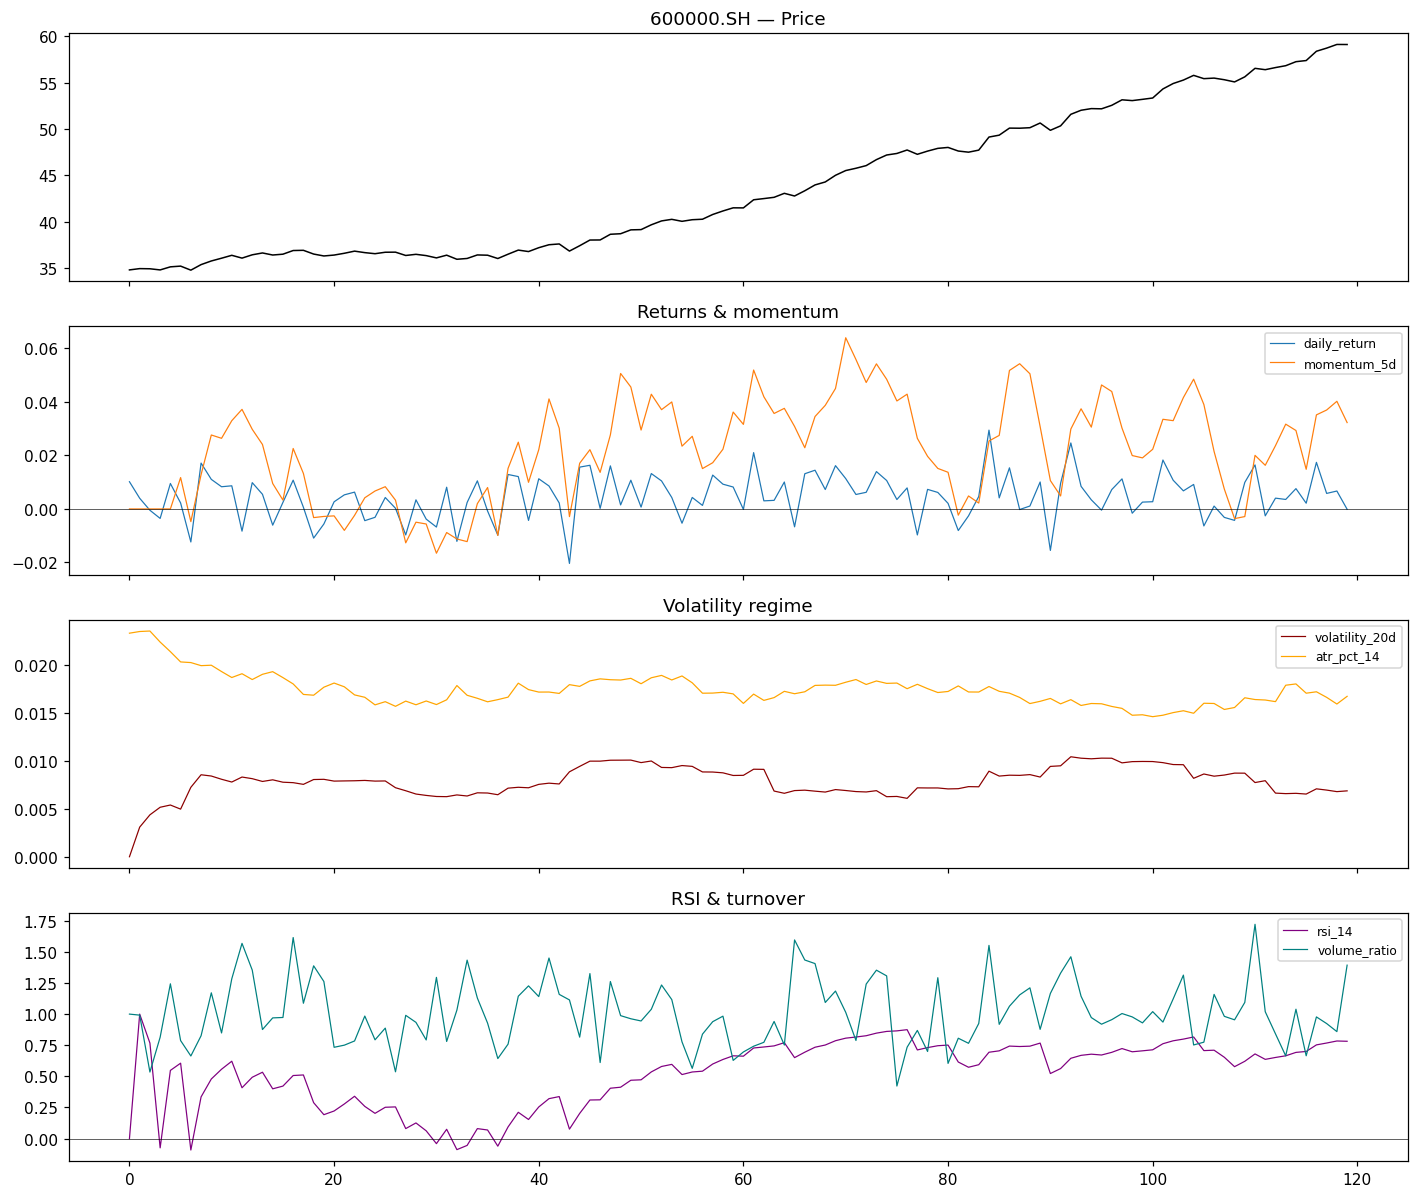

In [29]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
x = range(len(dates))
axes[0].plot(x, closes, lw=1.0, color="black"); axes[0].set_title(f"{sym} — Price")
axes[1].plot(x, history["daily_return"], lw=0.8, label="daily_return")
axes[1].plot(x, history["momentum_5d"], lw=0.8, label="momentum_5d")
axes[1].axhline(0, color="k", lw=0.4); axes[1].legend(fontsize=8)
axes[1].set_title("Returns & momentum")
axes[2].plot(x, history["volatility_20d"], lw=0.8, color="darkred", label="volatility_20d")
axes[2].plot(x, history["atr_pct_14"], lw=0.8, color="orange", label="atr_pct_14")
axes[2].legend(fontsize=8); axes[2].set_title("Volatility regime")
axes[3].plot(x, history["rsi_14"], lw=0.8, color="purple", label="rsi_14")
axes[3].plot(x, history["volume_ratio"], lw=0.8, color="teal", label="volume_ratio")
axes[3].axhline(0, color="k", lw=0.4); axes[3].legend(fontsize=8)
axes[3].set_title("RSI & turnover")
plt.tight_layout(); plt.show()

## 4. Cross-Sectional Standardization

The engine z-scores each factor within the day's universe before applying β.

In [30]:
factors_panel = factor_panel_to_dict(factor_df)
engine = TradingEngine(factors=factors_panel)
d = dates[-1]
cs = engine.build_cross_section(d, bars_panel[d])
print(f"Date {d}: {len(cs.symbols)} stocks")
for i, s in enumerate(cs.symbols[:4]):
    raw = cs.factors_by_symbol[s]["momentum_5d"]
    z = cs.z_matrix[i, FACTOR_NAMES.index("momentum_5d")]
    print(f"  {s:<12s}  raw={raw:+.6f}  z={z:+.4f}")

Date 20200220: 5 stocks
  600000.SH     raw=+0.032275  z=+0.3770
  600001.SH     raw=-0.092013  z=-1.9169
  600002.SH     raw=+0.022551  z=+0.1975
  600003.SH     raw=+0.067106  z=+1.0199


## 5. Signal Generation — Raw Mode

In [31]:
engine_raw = TradingEngine(factors=factors_panel, raw_thresholds={
    "momentum_5d": 0.02, "rsi_14": 0.30, "ma_dev_20": 0.02})
out = engine_raw.on_cross_section(d, bars_panel[d])
print(f"Date {d}: {len(out)} stocks have signals")
for sym, sigs in list(out.items())[:4]:
    for s in sigs:
        print(f"  {s}")

Date 20200220: 5 stocks have signals
  Signal(600000.SH momentum_5d: LONG, strength=0.03227)
  Signal(600000.SH ma_dev_20: LONG, strength=0.04896)
  Signal(600000.SH rsi_14: LONG, strength=0.78181)
  Signal(600001.SH momentum_5d: FLAT, strength=0.09201)
  Signal(600001.SH ma_dev_20: FLAT, strength=0.11887)
  Signal(600001.SH rsi_14: FLAT, strength=0.37911)
  Signal(600002.SH momentum_5d: LONG, strength=0.02255)
  Signal(600003.SH momentum_5d: LONG, strength=0.06711)
  Signal(600003.SH ma_dev_20: LONG, strength=0.05904)
  Signal(600003.SH rsi_14: LONG, strength=0.37467)


---

## 6. Factor Calibration — Fama-MacBeth (on parquet-loaded data)

The **full pipeline now runs off disk**: simulate → write parquet → load with
polars → compute factors → calibrate.

In [32]:
# Simulate → write parquet → load back with polars (the real data path).
bars_inmem, uni_inmem, mkt_inmem = generate_simulated_market(n_stocks=30, n_days=250, seed=7)
root_full = tempfile.mkdtemp(prefix="alftrade_full_")
write_market_parquet(bars_inmem, uni_inmem, mkt_inmem, root_full)

panel_full, factors_full, uni_full, _ = load_market_with_factors(root_full)
dates_full = panel_full.dates
split = dates_full[:-30]
print(f"Loaded parquet panel: {len(dates_full)} dates × {len(uni_full.symbols)} stocks")

offline_engine = TradingEngine(factors=factors_full)
calibrator = FactorCalibrator(horizon=5, alpha=1.0, min_samples=50, min_dates=10)
for d in split:
    cs = offline_engine.build_cross_section(d, panel_full[d])
    calibrator.collect(d, cs, panel_full)

print(f"Collected {calibrator.num_samples} pairs over {calibrator.num_dates} dates")

Loaded parquet panel: 250 dates × 30 stocks
Collected 6450 pairs over 215 dates


In [33]:
result = calibrator.fit(method="fama_macbeth")
print(result)

CalibrationResult(horizon=5, method=fama_macbeth, alpha=1.0, n=6450, T=215, R²=0.2450), date=2026-08-17T06:29:32.103510+00:00
  Factor                 Beta   t-stat       IC       IR
  ---------------- ---------- -------- -------- --------
  daily_return       -0.00080    -2.76  -0.0059   -0.042
  overnight_return   -0.00024    -0.55  -0.0116   -0.074
  intraday_return    -0.00067    -2.43  -0.0022   -0.020
  momentum_5d        -0.00235    -3.30   0.0612    0.299
  momentum_20d       -0.00101    -1.27   0.1297    0.687
  ma_dev_20           0.00091     1.00   0.1263    0.673
  volatility_20d     -0.00443    -6.34  -0.2282   -1.114
  volume_ratio        0.00074     1.76   0.0216    0.132
  rsi_14              0.00278     3.12   0.1469    0.835
  atr_pct_14         -0.00342    -4.57  -0.2297   -1.226
  market_beta        -0.00067    -1.57  -0.0602   -0.328


---

## 7. Factor Profiler

In [34]:
profiler = FactorProfiler.from_calibrator(calibrator, n_quantiles=5)
model_profile = profiler.profile()
print(model_profile)

ModelProfile(n=6450, T=215, k=11, model_IC=0.2540, model_mono=1.0000, L−S=0.02665)
  Factor                 Beta    t-stat         IC      IR       L−S   turn    mono
  ---------------- ---------- ---------    ------- ------- --------- ------ -------
  daily_return     β=  -0.00080 t=  -2.76**  IC=-0.0059 IR= -0.042 L−S=-0.00114 turn= 0.340 mono= -0.100
  overnight_return β=  -0.00024 t=  -0.55    IC=-0.0116 IR= -0.074 L−S=-0.00202 turn= 0.344 mono= -0.400
  intraday_return  β=  -0.00067 t=  -2.43*   IC=-0.0022 IR= -0.020 L−S=-0.00068 turn= 0.340 mono= -0.100
  momentum_5d      β=  -0.00235 t=  -3.30**  IC= 0.0612 IR=  0.299 L−S= 0.00541 turn= 0.150 mono=  0.700
  momentum_20d     β=  -0.00101 t=  -1.27    IC= 0.1297 IR=  0.687 L−S= 0.01092 turn= 0.065 mono=  0.900
  ma_dev_20        β=   0.00091 t=   1.00    IC= 0.1263 IR=  0.673 L−S= 0.01177 turn= 0.093 mono=  1.000
  volatility_20d   β=  -0.00443 t=  -6.34*** IC=-0.2282 IR= -1.114 L−S=-0.02212 turn= 0.048 mono= -1.000
  volume_ratio

---

# Part II — Portfolio & Risk

## 8. From Signals to Portfolio

In [35]:
live_engine = TradingEngine(factors=factors_full, calibration=result)
pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                      aggregator=SignalAggregator(calibration=result))
d0 = dates_full[-30]
sigs = live_engine.on_cross_section(d0, panel_full[d0])
trades = pm.decide(d0, panel_full[d0], sigs)
print(f"Date {d0}: {len(trades)} trades")
for t in trades:
    print(f"  {t}")
print(f"Equity: {pm.portfolio.mark_to_market(panel_full[d0]):,.0f}")

Date 20200321: 5 trades
  Trade(20200321 600007.SH OPEN qty=+6600 @ 30.10 cost=53.65 pnl=0.00 [REBALANCE])
  Trade(20200321 600026.SH OPEN qty=+2400 @ 81.33 cost=52.70 pnl=0.00 [REBALANCE])
  Trade(20200321 600000.SH OPEN qty=+2800 @ 70.21 cost=53.08 pnl=0.00 [REBALANCE])
  Trade(20200321 600008.SH OPEN qty=+2400 @ 83.03 cost=53.80 pnl=0.00 [REBALANCE])
  Trade(20200321 600006.SH OPEN qty=+5200 @ 38.05 cost=53.42 pnl=0.00 [REBALANCE])
Equity: 999,733


## 9. Equity Curve

In [36]:
pm = PortfolioManager(capital=1_000_000.0, n_holdings=5, weighting="equal",
                      aggregator=SignalAggregator(calibration=result))
live_engine = TradingEngine(factors=factors_full, calibration=result)
held_out = dates_full[-30:]
equity_hist, npos_hist = [], []
all_syms = sorted(uni_full.symbols)
sym_idx = {s: i for i, s in enumerate(all_syms)}
score_matrix = np.full((len(held_out), len(all_syms)), np.nan)
weight_matrix = np.zeros((len(held_out), len(all_syms)))

for t, d in enumerate(held_out):
    sigs = live_engine.on_cross_section(d, panel_full[d])
    pm.decide(d, panel_full[d], sigs)
    for sym, lst in sigs.items():
        s = lst[0]
        score_matrix[t, sym_idx[sym]] = s.strength if s.direction > 0 else -s.strength
    eq = pm.portfolio.mark_to_market(panel_full[d])
    for sym, pos in pm.portfolio.positions.items():
        if pos.quantity > 0:
            weight_matrix[t, sym_idx[sym]] = pos.quantity * panel_full[d][sym].close / eq
    equity_hist.append(eq)
    npos_hist.append(sum(1 for p in pm.portfolio.positions.values() if p.quantity > 0))

portfolio_return = np.array(equity_hist[1:]) / np.array(equity_hist[:-1]) - 1
print(f"Final equity:  {equity_hist[-1]:,.0f}  ({(equity_hist[-1]/1e6-1)*100:+.2f}%)")
print(f"Total trades:  {len(pm.trades)}")

Final equity:  1,076,681  (+7.67%)
Total trades:  86


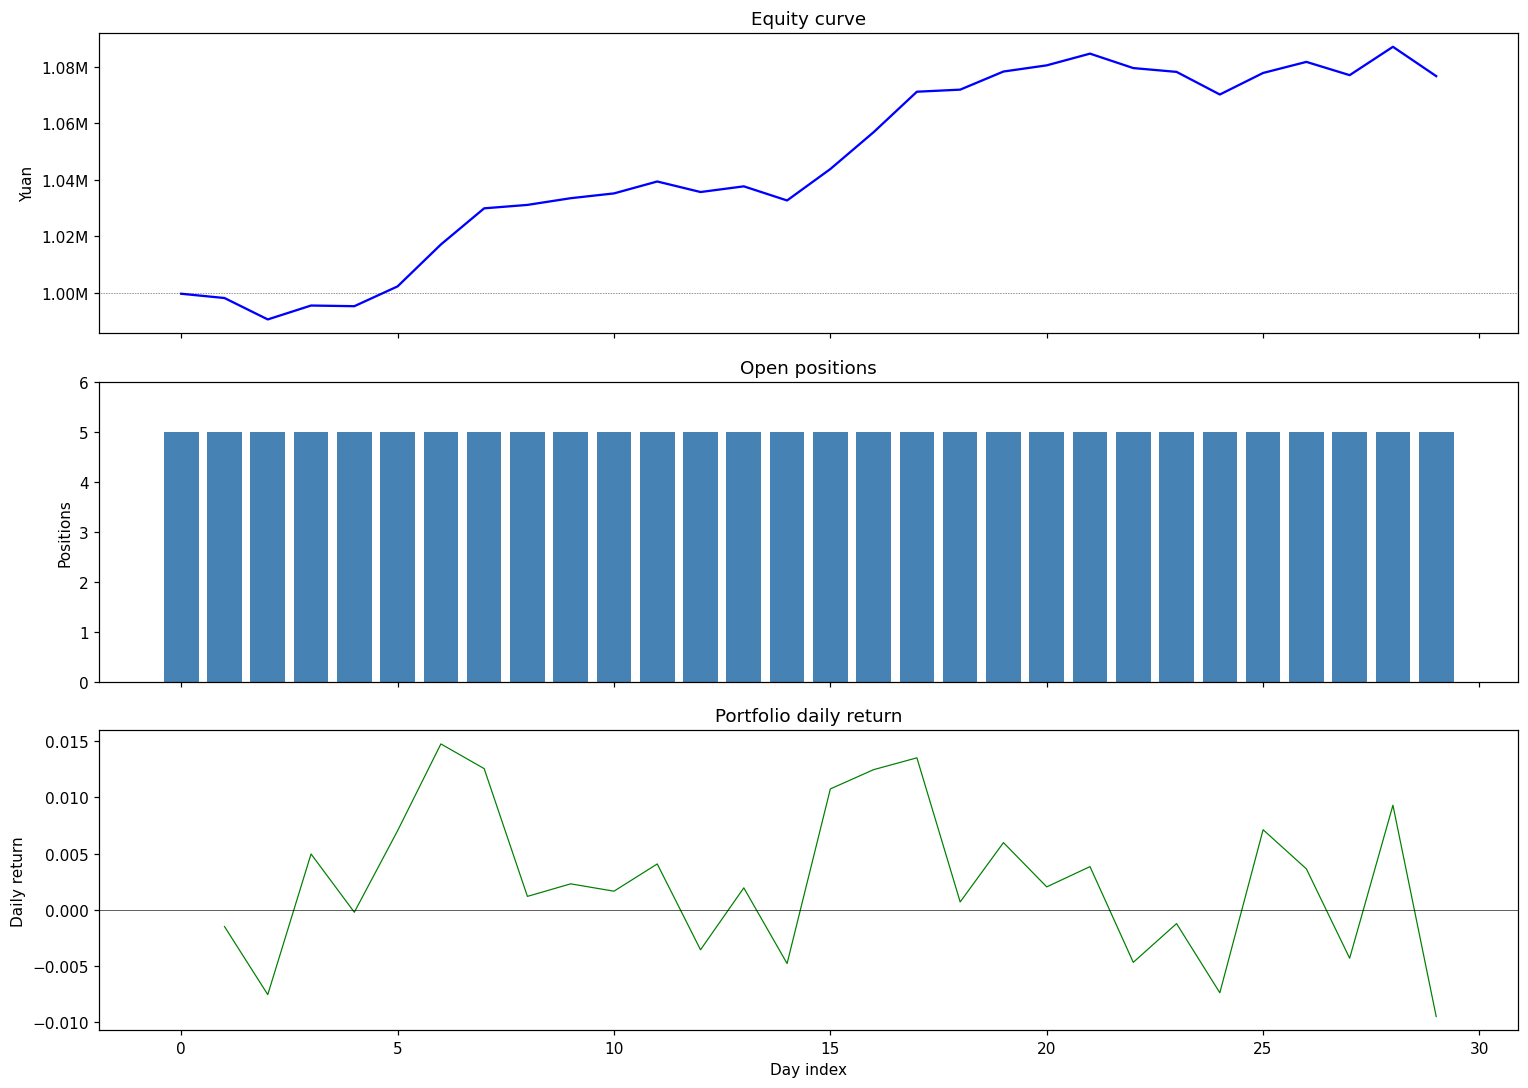

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
x = range(len(held_out))
axes[0].plot(x, equity_hist, lw=1.5, color="blue"); axes[0].axhline(1e6, color="k", lw=0.4, ls=":")
axes[0].set_ylabel("Yuan"); axes[0].set_title("Equity curve")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))
axes[1].bar(x, npos_hist, color="steelblue"); axes[1].set_ylim(0, max(npos_hist)+1)
axes[1].set_ylabel("Positions"); axes[1].set_title("Open positions")
axes[2].plot(x[1:], portfolio_return, lw=0.8, color="green"); axes[2].axhline(0, color="k", lw=0.4)
axes[2].set_ylabel("Daily return"); axes[2].set_xlabel("Day index")
axes[2].set_title("Portfolio daily return")
plt.tight_layout(); plt.show()

## 9a. Cross-Sectional Signal Heatmap

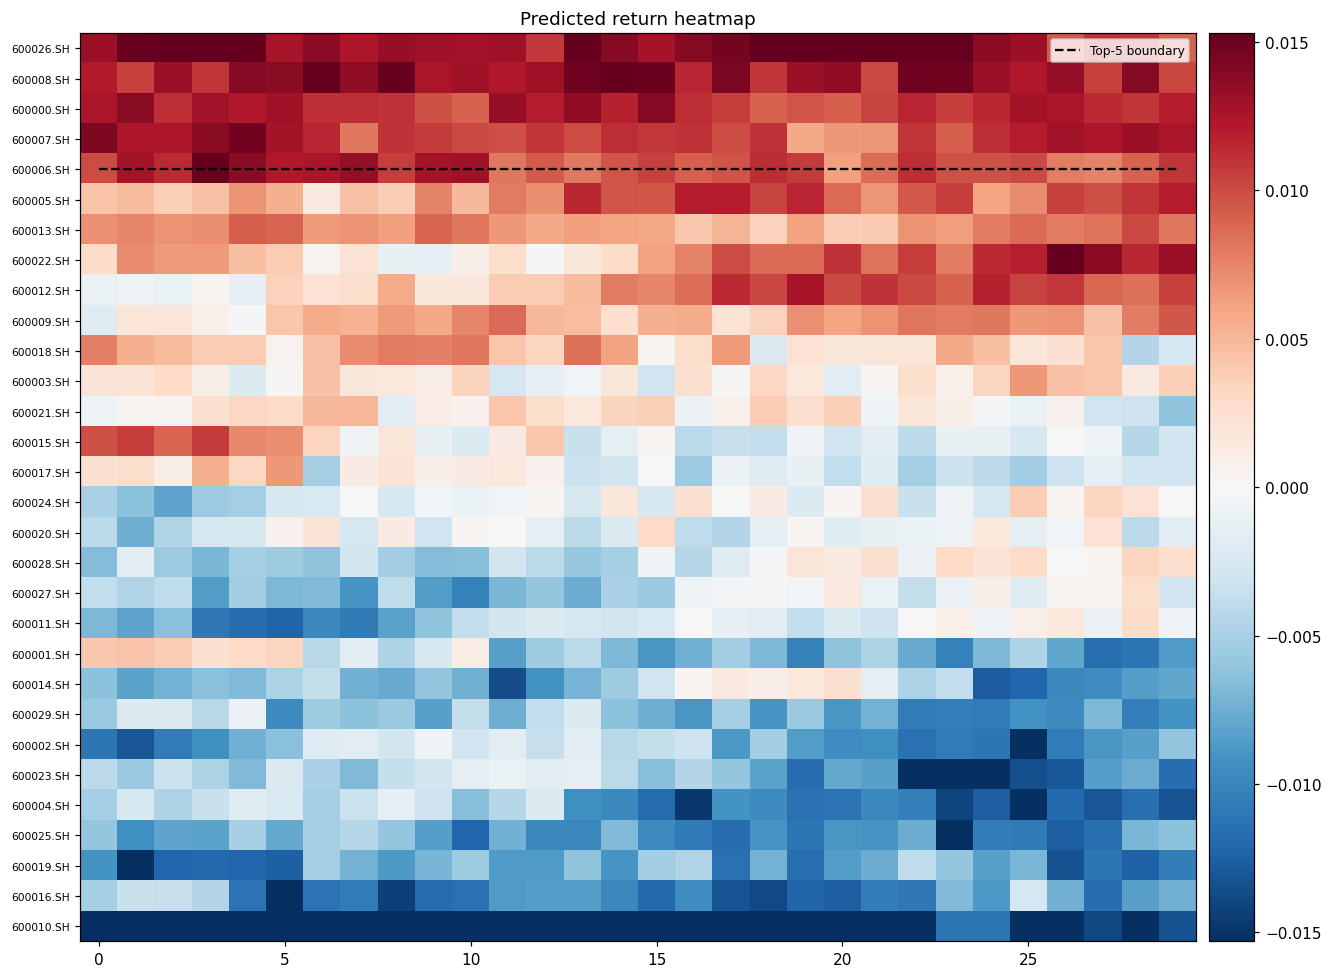

In [38]:
mean_score = np.nanmean(score_matrix, axis=0)
order = np.argsort(-mean_score)
score_ordered = score_matrix[:, order]
syms_ordered = [all_syms[i] for i in order]
fig, ax = plt.subplots(figsize=(13, 9))
vmax = np.nanpercentile(abs(score_ordered), 95)
ax.imshow(score_ordered.T, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
          extent=[-0.5, len(held_out)-0.5, len(all_syms)-0.5, -0.5])
boundary_y = []
for t in range(len(held_out)):
    col = score_ordered[t]; valid = np.where(~np.isnan(col))[0]
    boundary_y.append(valid[4] if valid.size >= 5 else np.nan)
ax.plot(range(len(held_out)), boundary_y, "k--", lw=1.5, label="Top-5 boundary")
ax.set_yticks(range(len(syms_ordered))); ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_title("Predicted return heatmap"); ax.legend(fontsize=8)
fig.colorbar(ax.images[0], ax=ax, pad=0.01)
plt.tight_layout(); plt.show()

## 9b. Position Occupancy Heatmap

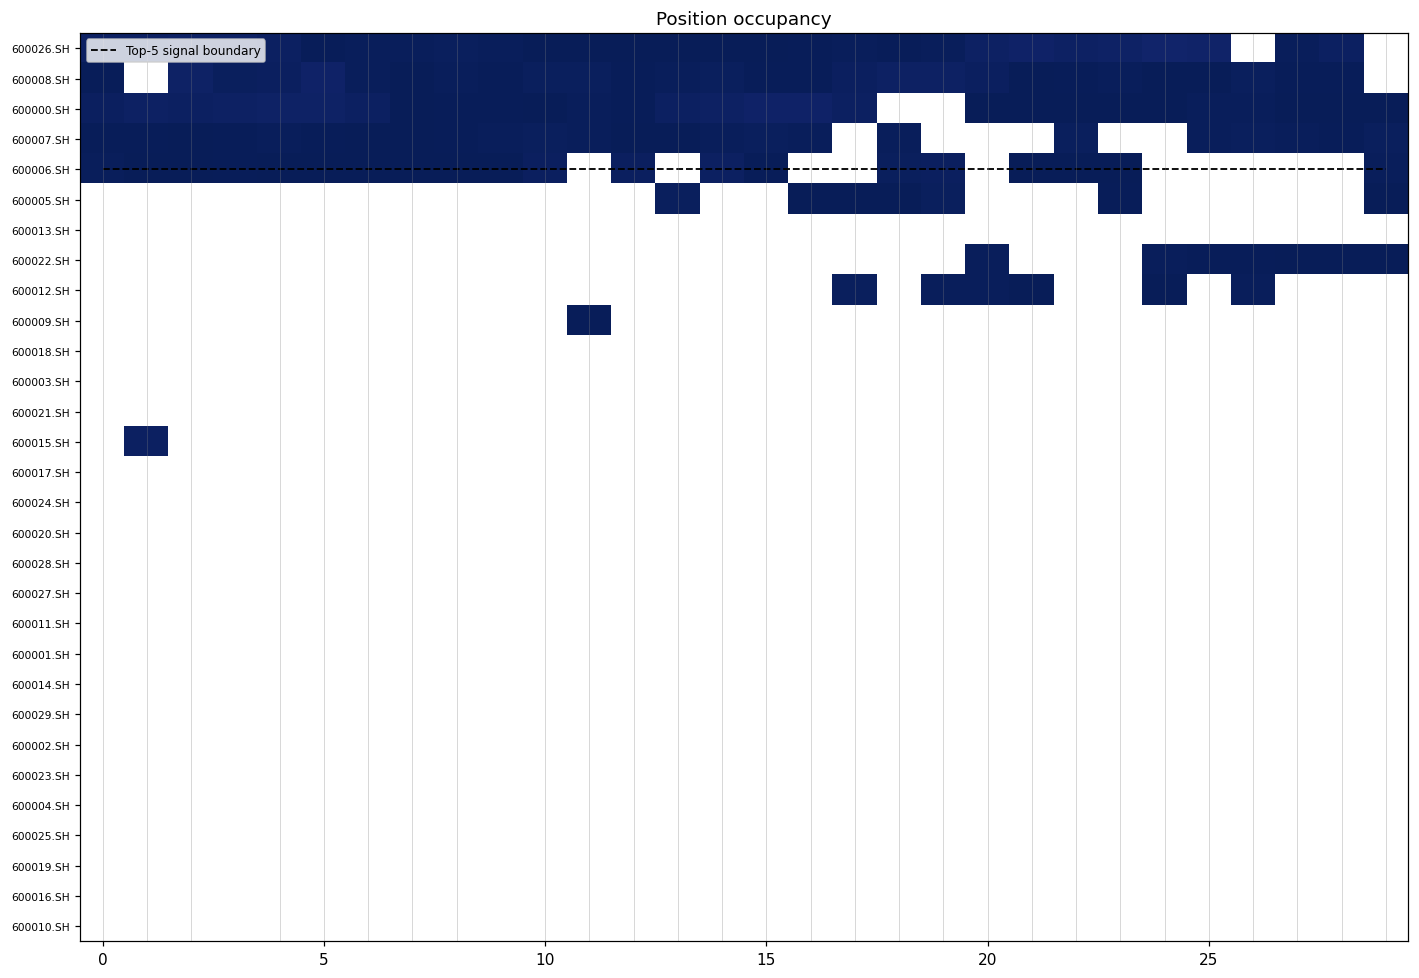

Mean daily weight turnover: 0.3184  (~31.8%/day)
Stocks ever held: 10 / 30


In [39]:
weight_ordered = weight_matrix[:, order]
masked = np.ma.masked_where(weight_ordered.T == 0, weight_ordered.T)
cmap = plt.cm.YlGnBu.copy(); cmap.set_bad(color="white")
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(masked, aspect="auto", cmap=cmap, vmin=0, vmax=max(weight_matrix.max(), 1e-6),
          extent=[-0.5, len(held_out)-0.5, len(all_syms)-0.5, -0.5])
ax.plot(range(len(held_out)), boundary_y, "k--", lw=1.2, label="Top-5 signal boundary")
rebal = [t for t, d in enumerate(held_out) if any(tr.date == d for tr in pm.trades)]
for t in rebal:
    ax.axvline(t, color="gray", lw=0.4, alpha=0.5)
ax.set_yticks(range(len(syms_ordered))); ax.set_yticklabels(syms_ordered, fontsize=7)
ax.set_title("Position occupancy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
turnover = np.abs(np.diff(weight_matrix, axis=0)).sum(axis=1).mean()
print(f"Mean daily weight turnover: {turnover:.4f}  (~{turnover*100:.1f}%/day)")
print(f"Stocks ever held: {int((weight_matrix > 0).any(axis=0).sum())} / {len(all_syms)}")

## 10. Style Exposure

In [40]:
mkt_return = np.array([panel_full[d][uni_full.symbols[0]].market_return for d in held_out[1:]])
X = np.column_stack([np.ones_like(mkt_return), mkt_return])
coeff = np.linalg.lstsq(X, portfolio_return, rcond=None)[0]
print(f"Style exposure:  alpha={coeff[0]:+.5f} ({coeff[0]*252*100:+.2f}% ann), "
      f"beta_market={coeff[1]:+.3f}")

Style exposure:  alpha=+0.00324 (+81.64% ann), beta_market=+1.185


## 11. Short-Index-Futures Hedge

In [41]:
index_start = 5500.0
index_level = np.zeros(len(held_out)); index_level[0] = index_start
cum = 1.0
for t in range(1, len(held_out)):
    cum *= (1.0 + panel_full[held_out[t]][uni_full.symbols[0]].market_return)
    index_level[t] = index_start * cum

hm = HedgeManager(contract=FuturesContract("IM", multiplier=100.0),
                  beta_window=20, min_beta_t=0.0, max_leverage=1.5)
hedge_pnl_hist, beta_hist = [], []
for t, d in enumerate(held_out):
    pr = portfolio_return[t] if t < len(portfolio_return) else 0.0
    mr = panel_full[d][uni_full.symbols[0]].market_return
    pnl, lots, beta = hm.step(d, equity_hist[t], pr, mr, index_level[t])
    hedge_pnl_hist.append(pnl); beta_hist.append(beta)
hedged_equity = compute_hedged_equity(equity_hist, [], hedge_pnl_hist)
print(f"Hedge cumulative PnL = {hm.cumulative_pnl:+,.0f} yuan")
print(f"  Raw final: {equity_hist[-1]:,.0f}   Hedged final: {hedged_equity[-1]:,.0f}")

Hedge cumulative PnL = +7,489 yuan
  Raw final: 1,076,681   Hedged final: 1,085,992


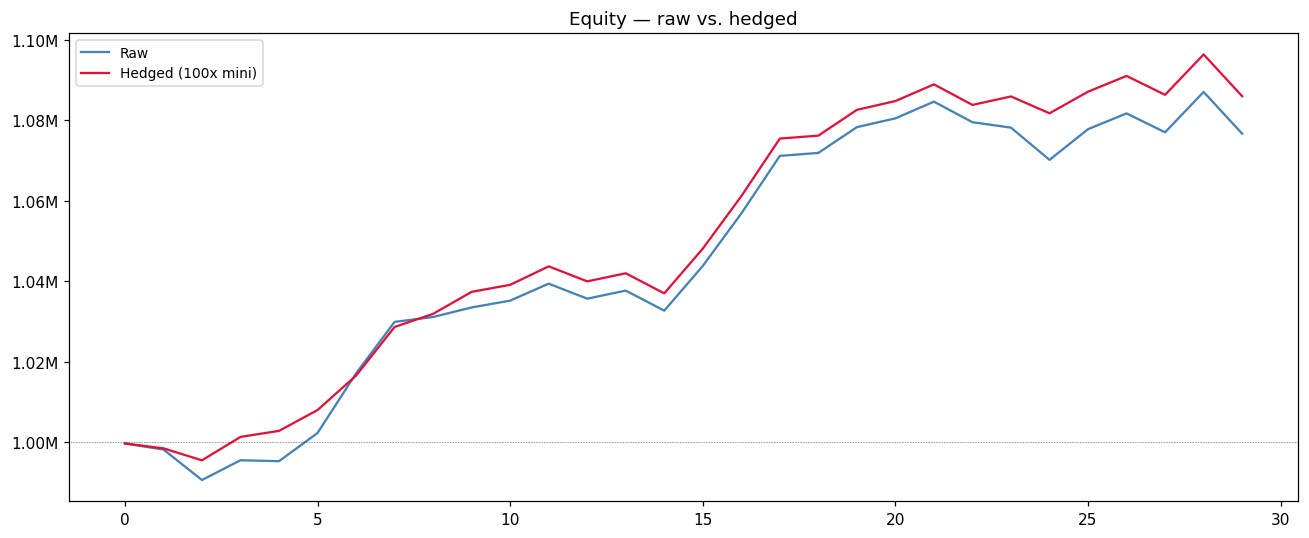

In [42]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(range(len(held_out)), equity_hist, lw=1.5, color="steelblue", label="Raw")
ax.plot(range(len(held_out)), hedged_equity, lw=1.5, color="crimson", label="Hedged (100x mini)")
ax.axhline(1e6, color="k", lw=0.4, ls=":"); ax.legend(fontsize=9)
ax.set_title("Equity — raw vs. hedged")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.2f}M"))
plt.tight_layout(); plt.show()

## 12. Risk Management

In [43]:
risk_cfg = RiskConfig(max_weight_per_name=0.25, max_notional_per_trade=200_000,
                      stop_loss_pct=0.08, max_drawdown_pct=0.15, daily_loss_limit_pct=0.03)
pm_risk = PortfolioManager(capital=1_000_000.0, n_holdings=5,
                           aggregator=SignalAggregator(calibration=result),
                           risk_manager=RiskManager(risk_cfg, initial_capital=1_000_000.0))
eng_risk = TradingEngine(factors=factors_full, calibration=result)
eq_risk = []
for d in held_out:
    pm_risk.decide(d, panel_full[d], eng_risk.on_cross_section(d, panel_full[d]))
    eq_risk.append(pm_risk.portfolio.mark_to_market(panel_full[d]))
print(f"With risk:    {(eq_risk[-1]/1e6-1)*100:+.2f}%  trades={len(pm_risk.trades)}")
print(f"Without risk: {(equity_hist[-1]/1e6-1)*100:+.2f}%  trades={len(pm.trades)}")
risk_trades = [t for t in pm_risk.trades if t.reason in
               ("STOP_LOSS", "TAKE_PROFIT", "MAX_DRAWDOWN", "DAILY_LOSS_LIMIT")]
print(f"Risk-triggered trades: {len(risk_trades)}")

With risk:    +7.66%  trades=100
Without risk: +7.67%  trades=86
Risk-triggered trades: 0


In [44]:
print("=== alftrade demo summary ===")
print(f"Panel:           {len(uni_full.symbols)} stocks × {len(dates_full)} days (parquet-loaded)")
print(f"Calibration:     Fama-MacBeth, T={result.n_dates}, n={result.sample_size}")
print(f"Model IC:        {model_profile.model_ic:+.4f}")
print(f"Significant:     {model_profile.selected_factors()}")
print(f"Backtest:        {len(held_out)} days, 5 holdings")
print(f"  Without risk:  {(equity_hist[-1]/1e6-1)*100:+.2f}%")
print(f"  With risk:     {(eq_risk[-1]/1e6-1)*100:+.2f}%")

=== alftrade demo summary ===
Panel:           30 stocks × 250 days (parquet-loaded)
Calibration:     Fama-MacBeth, T=215, n=6450
Model IC:        +0.2540
Significant:     ['daily_return', 'intraday_return', 'momentum_5d', 'volatility_20d', 'rsi_14', 'atr_pct_14']
Backtest:        30 days, 5 holdings
  Without risk:  +7.67%
  With risk:     +7.66%
